# Laboratory Tasks 3 and 4: Backpropagation and Linear Regression

<h3 style="font-family: Times New Roman"><strong>Laboratory Tasks 3 and 4</strong></h3>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">Answers for <b>Laboratory Task 3</b> (forward and backward propagation in Python) and <b>Laboratory Task 4</b> (linear regression with PyTorch).</p>

<h3 style="font-family: Times New Roman"><strong>Laboratory Task 3</strong></h3>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px"><b>Instruction:</b> Perform a forward and backward propagation in Python using the inputs from Laboratory Task 2 (ReLU activation, learning rate $= 0.001$).</p>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px">Loss: $E = \tfrac{1}{2}(\hat{y} - y)^2$. With ReLU, the derivative is $f'(Z) = 1$ if $Z > 0$ and $0$ otherwise. The backward pass uses:</p>

$$\delta_o = (\hat{y} - y)\cdot f'(Z_o) \qquad \delta_h = (\delta_o W_o^T)\cdot f'(Z_h)$$
$$\frac{\partial E}{\partial W_o} = H^T\delta_o \qquad \frac{\partial E}{\partial W_h} = x^T\delta_h \qquad \frac{\partial E}{\partial \theta} = \delta$$
$$W \leftarrow W - \alpha\,\frac{\partial E}{\partial W}$$

In [2]:
import numpy as np

x = np.array([1, 0, 1])
y = np.array([1])

relu      = lambda z: np.maximum(0, z)
relu_grad = lambda z: (z > 0).astype(float)

lr = 0.001

W_h = np.array([[ 0.2, -0.3],
                [ 0.4,  0.1],
                [-0.5,  0.2]])
W_o = np.array([[-0.3],
                [-0.2]])
theta_h = np.array([-0.4, 0.2])
theta_o = np.array([0.1])

Z_h   = x @ W_h + theta_h
H     = relu(Z_h)
Z_o   = H @ W_o + theta_o
y_hat = relu(Z_o)

loss = 0.5 * np.sum((y_hat - y) ** 2)
print("--- Forward pass ---")
print("Z_h   :", Z_h)
print("H     :", H)
print("Z_o   :", Z_o)
print("y_hat :", y_hat)
print("loss  :", loss)

delta_o = (y_hat - y) * relu_grad(Z_o)
delta_h = (delta_o @ W_o.T) * relu_grad(Z_h)

dW_o     = np.outer(H, delta_o)
dtheta_o = delta_o
dW_h     = np.outer(x, delta_h)
dtheta_h = delta_h

print("\n--- Backward pass ---")
print("delta_o  :", delta_o)
print("delta_h  :", delta_h)
print("dE/dW_o  :\n", dW_o)
print("dE/dW_h  :\n", dW_h)
print("dE/dtheta_o :", dtheta_o)
print("dE/dtheta_h :", dtheta_h)

W_o_new     = W_o - lr * dW_o
theta_o_new = theta_o - lr * dtheta_o
W_h_new     = W_h - lr * dW_h
theta_h_new = theta_h - lr * dtheta_h

print("\n--- Updated parameters (lr = 0.001) ---")
print("W_h :\n", W_h_new)
print("W_o :\n", W_o_new)
print("theta_h :", theta_h_new)
print("theta_o :", theta_o_new)

y_hat_new = relu(relu(x @ W_h_new + theta_h_new) @ W_o_new + theta_o_new)
print("\ny_hat before update:", y_hat, "| loss:", loss)
print("y_hat after  update:", y_hat_new, "| loss:", 0.5 * np.sum((y_hat_new - y) ** 2))

--- Forward pass ---
Z_h   : [-0.7  0.1]
H     : [0.  0.1]
Z_o   : [0.08]
y_hat : [0.08]
loss  : 0.4232

--- Backward pass ---
delta_o  : [-0.92]
delta_h  : [0.    0.184]
dE/dW_o  :
 [[-0.   ]
 [-0.092]]
dE/dW_h  :
 [[0.    0.184]
 [0.    0.   ]
 [0.    0.184]]
dE/dtheta_o : [-0.92]
dE/dtheta_h : [0.    0.184]

--- Updated parameters (lr = 0.001) ---
W_h :
 [[ 0.2      -0.300184]
 [ 0.4       0.1     ]
 [-0.5       0.199816]]
W_o :
 [[-0.3     ]
 [-0.199908]]
theta_h : [-0.4       0.199816]
theta_o : [0.10092]

y_hat before update: [0.08] | loss: 0.4232
y_hat after  update: [0.08103955] | loss: 0.42224415505256624


<p style="font-family:Times New Roman; text-align:justify; font-size:15px"><b>Observations:</b></p>
<ul style="font-family:Times New Roman; font-size:15px; text-align:justify">
<li>$H_1 = 0$ because $Z_1 = -0.7 < 0$, so ReLU outputs zero. Its derivative is also zero, so hidden unit 1 receives no gradient (a "dead" unit for this input). All gradient flows through hidden unit 2.</li>
<li>The output error $\delta_o = -0.92$ is negative, so the updates increase $\hat{y}$ toward the target of 1.</li>
<li>With $\alpha = 0.001$ the updates are very small, so the loss decreases only slightly after one step. More iterations would be needed to converge.</li>
</ul>

<h3 style="font-family: Times New Roman"><strong>Laboratory Task 4</strong></h3>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px"><b>Instruction:</b> Train a linear regression model in PyTorch using a regression dataset with: MSE loss, two fully connected layers, batch size 8, SGD optimizer, and 1000 epochs.</p>

<p style="font-family:Times New Roman; text-align:justify; font-size:15px"><b>Dataset:</b> scikit-learn's built-in <b>Diabetes</b> dataset (442 patients, 10 numeric features, target = disease progression one year after baseline). Features are standardized using the training set statistics, and the target is standardized as well so that SGD trains stably. Predictions are converted back to the original scale for the reported metrics.</p>

In [3]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Torch version:", torch.__version__)
print("Device:", device)

Torch version: 2.14.1+cu130
Device: cpu


<p style="font-family:Times New Roman; text-align:justify; font-size:15px"><b>1. Load the dataset, split and scale</b></p>

In [4]:
data = load_diabetes()
X, y = data.data.astype("float32"), data.target.astype("float32").reshape(-1, 1)
print("X shape:", X.shape, "| y shape:", y.shape)
print("Features:", data.feature_names)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

x_mean, x_std = X_train.mean(0), X_train.std(0)
y_mean, y_std = y_train.mean(), y_train.std()

X_train_s = (X_train - x_mean) / x_std
X_test_s  = (X_test  - x_mean) / x_std
y_train_s = (y_train - y_mean) / y_std
y_test_s  = (y_test  - y_mean) / y_std

print("Train:", X_train_s.shape, "| Test:", X_test_s.shape)

X shape: (442, 10) | y shape: (442, 1)
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Train: (353, 10) | Test: (89, 10)


<p style="font-family:Times New Roman; text-align:justify; font-size:15px"><b>2. Dataset and DataLoader (batch size = 8)</b></p>

In [5]:
train_ds = TensorDataset(torch.from_numpy(X_train_s), torch.from_numpy(y_train_s))
test_ds  = TensorDataset(torch.from_numpy(X_test_s),  torch.from_numpy(y_test_s))

batch_size = 8
train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
test_dl  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False)

xb, yb = next(iter(train_dl))
print("One batch:", xb.shape, yb.shape)

One batch: torch.Size([8, 10]) torch.Size([8, 1])


<p style="font-family:Times New Roman; text-align:justify; font-size:15px"><b>3. Model: two fully connected layers (nn.Linear x 2)</b></p>

In [6]:
model = nn.Sequential(
    nn.Linear(10, 16),
    nn.Linear(16, 1),
).to(device)

print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Sequential(
  (0): Linear(in_features=10, out_features=16, bias=True)
  (1): Linear(in_features=16, out_features=1, bias=True)
)
Trainable parameters: 193


<p style="font-family:Times New Roman; text-align:justify; font-size:15px"><b>4 and 5. Loss function (MSE) and optimizer (SGD)</b></p>

In [7]:
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.001, momentum=0.9)
num_epochs = 1000

<p style="font-family:Times New Roman; text-align:justify; font-size:15px"><b>6. Training loop (1000 epochs)</b></p>

In [8]:
def evaluate(dl):
    model.eval()
    total, n = 0.0, 0
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            total += criterion(model(xb), yb).item() * len(xb)
            n += len(xb)
    return total / n

train_losses, test_losses = [], []

for epoch in range(num_epochs):
    model.train()
    running, n = 0.0, 0
    for xb, yb in train_dl:
        xb, yb = xb.to(device), yb.to(device)

        pred = model(xb)
        loss = criterion(pred, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running += loss.item() * len(xb)
        n += len(xb)

    train_losses.append(running / n)
    test_losses.append(evaluate(test_dl))

    if (epoch + 1) % 100 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1:4d}/{num_epochs}]  train MSE: {train_losses[-1]:.4f}  test MSE: {test_losses[-1]:.4f}")

Epoch [   1/1000]  train MSE: 0.8032  test MSE: 0.5783


Epoch [ 100/1000]  train MSE: 0.4834  test MSE: 0.4788


Epoch [ 200/1000]  train MSE: 0.4803  test MSE: 0.4778


Epoch [ 300/1000]  train MSE: 0.4852  test MSE: 0.4780


Epoch [ 400/1000]  train MSE: 0.4762  test MSE: 0.4718


...

Epoch [ 600/1000]  train MSE: 0.4792  test MSE: 0.4754


Epoch [ 700/1000]  train MSE: 0.4773  test MSE: 0.4874


Epoch [ 800/1000]  train MSE: 0.4771  test MSE: 0.4803


Epoch [ 900/1000]  train MSE: 0.4789  test MSE: 0.4764


Epoch [1000/1000]  train MSE: 0.4769  test MSE: 0.4793


<p style="font-family:Times New Roman; text-align:justify; font-size:15px"><b>Evaluation (original scale)</b></p>

In [9]:
model.eval()
with torch.no_grad():
    pred_test = model(torch.from_numpy(X_test_s).to(device)).cpu().numpy() * y_std + y_mean

mse  = float(np.mean((pred_test - y_test) ** 2))
rmse = mse ** 0.5
mae  = float(np.mean(np.abs(pred_test - y_test)))
r2   = r2_score(y_test, pred_test)

print(f"Test MSE : {mse:.2f}")
print(f"Test RMSE: {rmse:.2f}")
print(f"Test MAE : {mae:.2f}")
print(f"Test R^2 : {r2:.4f}")

print("\nFirst 8 test samples (actual vs predicted):")
for a, p in zip(y_test[:8].ravel(), pred_test[:8].ravel()):
    print(f"  actual = {a:7.1f}   predicted = {p:7.1f}")

Test MSE : 2912.40
Test RMSE: 53.97
Test MAE : 42.93
Test R^2 : 0.4503

First 8 test samples (actual vs predicted):
  actual =   219.0   predicted =   139.3
  actual =    70.0   predicted =   180.5
  actual =   202.0   predicted =   133.5
  actual =   230.0   predicted =   291.2
  actual =   111.0   predicted =   123.0
  actual =    84.0   predicted =    92.3
  actual =   242.0   predicted =   258.5
  actual =   272.0   predicted =   181.2


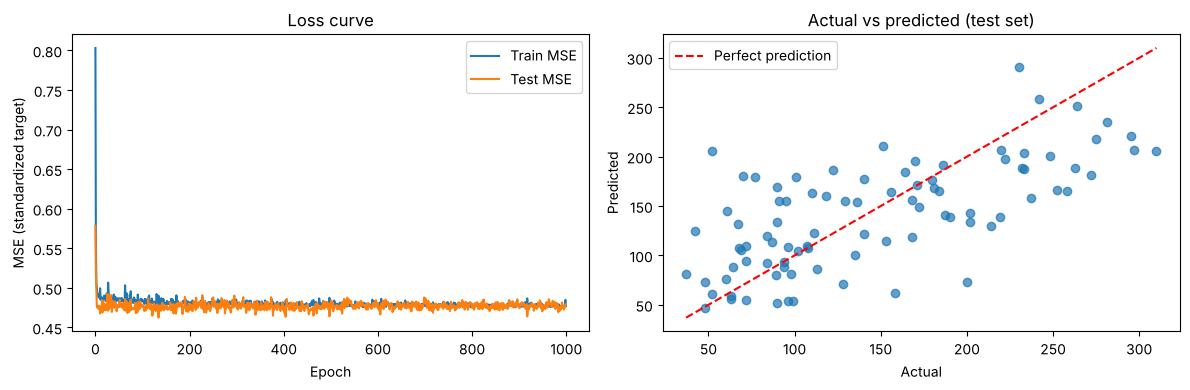

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(train_losses, label="Train MSE")
ax[0].plot(test_losses,  label="Test MSE")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("MSE (standardized target)")
ax[0].set_title("Loss curve"); ax[0].legend()

ax[1].scatter(y_test, pred_test, alpha=0.7)
lims = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
ax[1].plot(lims, lims, "r--", label="Perfect prediction")
ax[1].set_xlabel("Actual"); ax[1].set_ylabel("Predicted")
ax[1].set_title("Actual vs predicted (test set)"); ax[1].legend()

plt.tight_layout(); plt.show()

<p style="font-family:Times New Roman; text-align:justify; font-size:15px"><b>Notes:</b> Two stacked <tt>nn.Linear</tt> layers with no activation between them are still a linear model (the composition of two linear maps is linear), which is exactly what is asked for in a <i>linear regression</i> model. The loss levels off after a few hundred epochs, so the remaining epochs mainly fine-tune the weights. Diabetes progression is noisy, so an $R^2$ of roughly 0.45 to 0.5 is typical for a linear model on this dataset.</p>